# 02 · Feature Engineering Design Lab (Exploratory, No Dataset Export)

**Purpose:** identify, construct in-memory, visualize, and critique candidate features for the revised student-level prediction problems. This notebook is a *feature design lab*: it does **not** write training datasets or fit models.

## Prediction design being explored

We have 500 students, 2,453 quiz-attempt records, a student-level `dropped_out` outcome, and no reliable dropout timestamp. We use the last observed attempt only as a proxy for when a dropout may have occurred; it is not ground truth for the actual dropout date.

The requested feature families are:

1. **No-attempt / one-attempt unit:** all students are in scope; no attempt-derived features are available at the intended pre-attempt prediction point. Profile features (signup/device/country/age group/refund request, subject to availability and policy) can be explored. For the proposed early-dropout label, only students whose supplied dropout label is positive and whose observed history ends after at most one attempt are candidates for positive labels. This is a *proxy target*, not a confirmed time-stamped event.
2. **2–3 observed attempts unit:** the prediction point is the penultimate attempt. A two-attempt student contributes the current (first) attempt only; a three-attempt student contributes the previous and current (second) attempts. The label design needs careful interpretation: positive if the supplied dropout label is positive and the last observed attempt count is 2 or 3; otherwise negative for this bounded task. This label uses future history to define the retrospective outcome/cohort, not as a feature.
3. **3+ observed attempts unit:** prediction at penultimate attempt, using the full history available up to that point. Per-module history and progression features become more meaningful. For this group, the exploratory target proxy is positive for dropout-labelled students whose observed history ends after more than three attempts; the exact treatment of students with exactly 3 attempts belongs to the 2–3 group to avoid overlap.

> **Important identification caveat:** because the actual dropout date is missing, the data cannot prove that a student dropped out *after exactly k attempts*. The definitions above are operational cohort/label hypotheses to inspect, not validated event labels. In particular, if `dropped_out` is simply eventual status, a non-dropout-labelled student with few attempts is not necessarily an observed dropout at that horizon. Resolve this before model training.

**Leakage rule:** every feature shown below is computed only from static profile fields and/or attempts timestamped at or before the designated prediction attempt. We explicitly exclude the final attempt, future gaps, total eventual attempt count, and other future-derived values from feature candidates. Future history is used only in this notebook to describe retrospective cohort membership and proxy targets.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import display

sns.set_theme(style="whitegrid", context="notebook")
DATA_DIR = Path("../data")
if not (DATA_DIR / "students.csv").exists():
    # Also support running from the project root.
    DATA_DIR = Path("data")

students = pd.read_csv(DATA_DIR / "students.csv")
attempts = pd.read_csv(DATA_DIR / "quiz_attempts.csv")
outcomes = pd.read_csv(DATA_DIR / "outcome.csv")
explanations = pd.read_csv(DATA_DIR / "explanations.csv")

attempts["attempted_at"] = pd.to_datetime(attempts["attempted_at"], errors="coerce")
students["signup_date"] = pd.to_datetime(students["signup_date"], errors="coerce")
attempts["score_raw"] = pd.to_numeric(attempts["score"], errors="coerce")
# Sentinel handling: 999 is invalid, not a genuine score.
attempts["score_valid"] = attempts["score_raw"].mask(attempts["score_raw"].eq(999))
attempts["time_spent_min"] = pd.to_numeric(attempts["time_spent_min"], errors="coerce")
# Negative time is treated as invalid for candidate aggregate calculations; raw column retained.
attempts["time_valid_min"] = attempts["time_spent_min"].where(attempts["time_spent_min"].ge(0))

outcomes["dropped_out"] = outcomes["dropped_out"].astype(str).str.strip().str.lower()
print("Students:", students.shape, "Attempts:", attempts.shape, "Outcomes:", outcomes.shape, "Explanations:", explanations.shape)
print("Unique outcome labels:", outcomes["dropped_out"].value_counts(dropna=False).to_dict())
print("Score sentinel rows (999):", int(attempts["score_raw"].eq(999).sum()))
print("Missing timestamps:", int(attempts["attempted_at"].isna().sum()))
print("Missing durations:", int(attempts["time_valid_min"].isna().sum()))

Students: (500, 6) Attempts: (2453, 9) Outcomes: (500, 2) Explanations: (724, 5)
Unique outcome labels: {'no': 375, 'yes': 125}
Score sentinel rows (999): 3
Missing timestamps: 0
Missing durations: 95


## 1. Data inventory and caveats to carry into feature engineering

These checks are intentionally visible because feature aggregates can silently become misleading when missingness or invalid values are ignored.

In [2]:
inventory = pd.DataFrame({
    "table": ["students", "attempts", "outcomes", "explanations"],
    "rows": [len(students), len(attempts), len(outcomes), len(explanations)],
    "columns": [students.shape[1], attempts.shape[1], outcomes.shape[1], explanations.shape[1]],
})
display(inventory)

caveats = pd.DataFrame([
    ("Score = 999", int(attempts["score_raw"].eq(999).sum()), "Sentinel / invalid score; exclude from score means, medians, ranges, plots, and progression features. Preserve raw value and add invalid-score indicator if useful."),
    ("Missing score", int(attempts["score_valid"].isna().sum()), "Do not replace with zero. Keep valid-score count and missing-score indicators; aggregates need min_count / valid-count checks."),
    ("Missing or invalid duration", int(attempts["time_valid_min"].isna().sum()), "Do not assume zero minutes. Add valid-duration count and missing-duration fraction; consider robust statistics because durations can be skewed."),
    ("Missing attempt timestamp", int(attempts["attempted_at"].isna().sum()), "Chronology and prediction-time filtering cannot be trusted for these rows. Audit and exclude from time-ordered features unless a defensible order exists."),
    ("Students without attempts", int(students["student_id"].nunique() - attempts["student_id"].nunique()), "No attempt-derived features exist. This is not equivalent to score=0 or poor performance."),
    ("Repeated student-module pairs", int(attempts.duplicated(["student_id", "lesson_id"]).sum()), "Expected for retakes; distinguish attempt count from unique module exposure and calculate first/latest only within the observed prefix."),
    ("No dropout timestamp", np.nan, "Last observed attempt is only a proxy. Do not describe it as a confirmed dropout date or use the final attempt as a predictor at penultimate time."),
    ("Potentially sensitive/profile fields", np.nan, "Country, age group, device, refund request may require product, fairness, privacy, and policy review before modeling."),
], columns=["caveat", "rows_or_count", "feature-engineering implication"])
display(caveats)

,table,rows,columns
0,students,500,6
1,attempts,2453,9
2,outcomes,500,2
3,explanations,724,5


,caveat,rows_or_count,feature-engineering implication
0,Score = 999,3.0,Sentinel / invalid score; exclude from score m...
1,Missing score,3.0,Do not replace with zero. Keep valid-score cou...
2,Missing or invalid duration,95.0,Do not assume zero minutes. Add valid-duration...
3,Missing attempt timestamp,0.0,Chronology and prediction-time filtering canno...
4,Students without attempts,1.0,No attempt-derived features exist. This is not...
5,Repeated student-module pairs,1190.0,Expected for retakes; distinguish attempt coun...
6,No dropout timestamp,NaN,Last observed attempt is only a proxy. Do not ...
7,Potentially sensitive/profile fields,NaN,"Country, age group, device, refund request may..."


## 2. Construct the retrospective cohorts and proxy labels (diagnostics only)

This section uses eventual attempt counts **only to define retrospective cohorts and target hypotheses**. They must never be included as predictors. Counts are based on all recorded attempt rows, including rows with invalid score/duration, because an attempt still occurred. Students with no attempt records remain in the first unit.

In [3]:
attempt_counts = attempts.groupby("student_id").size().rename("observed_attempt_count")
base = students.merge(outcomes, on="student_id", how="left").merge(attempt_counts, on="student_id", how="left")
base["observed_attempt_count"] = base["observed_attempt_count"].fillna(0).astype(int)
base["dropout_label_positive"] = base["dropped_out"].eq("yes")

def assign_group(n):
    if n <= 1: return "A: 0–1 attempts"
    if n <= 3: return "B: 2–3 attempts"
    return "C: 4+ attempts"
base["retrospective_group"] = base["observed_attempt_count"].map(assign_group)
# Candidate proxy labels for comparison only; these definitions are not validated event-time labels.
base["proxy_target_A"] = (base["dropout_label_positive"] & base["observed_attempt_count"].le(1)).astype(int)
base["proxy_target_B"] = (base["dropout_label_positive"] & base["observed_attempt_count"].between(2, 3)).astype(int)
base["proxy_target_C"] = (base["dropout_label_positive"] & base["observed_attempt_count"].ge(4)).astype(int)

display(base.groupby(["retrospective_group", "dropped_out"], dropna=False).size().rename("students").reset_index())
print("Group counts:")
display(base["retrospective_group"].value_counts().rename_axis("group").to_frame("students"))
print("Proxy target prevalence by retrospective group (diagnostic only):")
display(base.groupby("retrospective_group")[["proxy_target_A", "proxy_target_B", "proxy_target_C"]].mean().round(3))

,retrospective_group,dropped_out,students
0,A: 0–1 attempts,no,1
1,A: 0–1 attempts,yes,21
2,B: 2–3 attempts,no,54
3,B: 2–3 attempts,yes,50
4,C: 4+ attempts,no,320
5,C: 4+ attempts,yes,54


Group counts:


,students
group,
C: 4+ attempts,374
B: 2–3 attempts,104
A: 0–1 attempts,22


Proxy target prevalence by retrospective group (diagnostic only):


,proxy_target_A,proxy_target_B,proxy_target_C
retrospective_group,,,
A: 0–1 attempts,0.955,0.000,0.000
B: 2–3 attempts,0.000,0.481,0.000
C: 4+ attempts,0.000,0.000,0.144


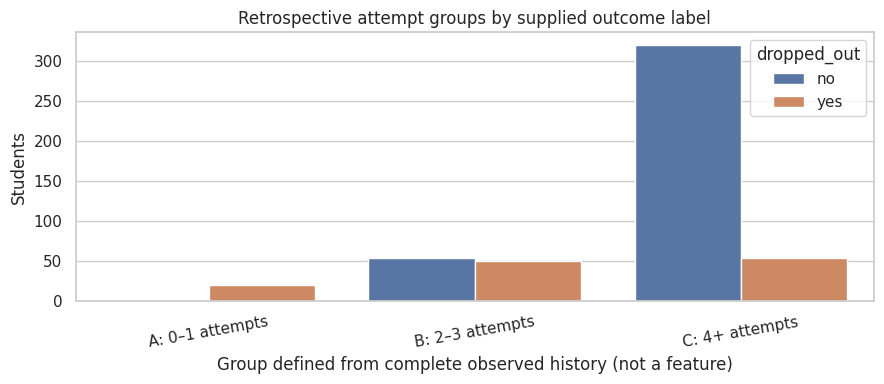

In [4]:
plt.figure(figsize=(9, 4))
sns.countplot(data=base, x="retrospective_group", hue="dropped_out", order=["A: 0–1 attempts", "B: 2–3 attempts", "C: 4+ attempts"])
plt.title("Retrospective attempt groups by supplied outcome label")
plt.xlabel("Group defined from complete observed history (not a feature)")
plt.ylabel("Students")
plt.xticks(rotation=10)
plt.tight_layout(); plt.show()

### Target definition warning

A group-specific positive proxy as defined above is a conjunction of the eventual outcome and eventual attempt count. That is useful for exploring the proposed question, but it is **not evidence that dropout occurred at that attempt boundary**. If the actual product objective is “predict eventual dropout at a specified prediction point,” the eventual `dropped_out` label may be the correct target for every eligible student, and attempt count should define *available information at prediction time*, not redefine the outcome. Compare both target formulations with the project owner before training.

## 3. Prediction-point snapshots without future features

We sort each student's attempts chronologically and make a prefix snapshot at the designated penultimate attempt. This table is in-memory and is used only for feature design / visualization. The feature function never reads rows after `prediction_time`.

- For a student with 2 attempts, prediction index is the first attempt: only current attempt information exists.
- For 3 attempts, prediction index is the second attempt: previous + current attempt are available.
- For 4+ attempts, prediction index is the second-to-last recorded attempt, with the complete prefix up to that point.
- For 0–1 attempts, there is no valid penultimate attempt; use profile-only features and clearly document the prediction time assumption.

In [5]:
# Stable chronology. Rows without timestamps are sorted last and are not considered reliable for temporal snapshots.
attempts_sorted = attempts.sort_values(["student_id", "attempted_at", "attempt_id"], na_position="last").copy()
attempts_sorted["attempt_number_observed"] = attempts_sorted.groupby("student_id").cumcount() + 1
attempts_sorted["_global_chronology_order"] = np.arange(len(attempts_sorted))

snapshot_rows = []
for sid, g in attempts_sorted.groupby("student_id", sort=False):
    g = g.reset_index(drop=True)
    n = len(g)
    if n <= 1:
        continue
    # Penultimate attempt index, zero-based. Only this prefix is visible to feature engineering.
    pred_idx = n - 2
    prefix = g.iloc[:pred_idx + 1].copy()
    current = prefix.iloc[-1]
    previous = prefix.iloc[-2] if len(prefix) >= 2 else None
    row = {
        "student_id": sid,
        "observed_attempt_count_for_cohort_only": n,  # never a predictor
        "prediction_attempt_number": len(prefix),
        "prediction_time": current["attempted_at"],
        "prediction_order_index": int(current["_global_chronology_order"]),
        "current_score": current["score_valid"],
        "current_time_spent_min": current["time_valid_min"],
        "has_previous_attempt": previous is not None,
        "previous_score": previous["score_valid"] if previous is not None else np.nan,
        "previous_time_spent_min": previous["time_valid_min"] if previous is not None else np.nan,
        "prefix_attempts": len(prefix),
        "prefix_valid_score_count": int(prefix["score_valid"].notna().sum()),
        "prefix_valid_duration_count": int(prefix["time_valid_min"].notna().sum()),
        "prefix_score_mean": prefix["score_valid"].mean(),
        "prefix_score_median": prefix["score_valid"].median(),
        "prefix_score_std": prefix["score_valid"].std(ddof=0) if prefix["score_valid"].notna().sum() else np.nan,
        "prefix_time_mean": prefix["time_valid_min"].mean(),
        "prefix_time_sum": prefix["time_valid_min"].sum(min_count=1),
        "prefix_missing_score_rate": prefix["score_valid"].isna().mean(),
        "prefix_missing_duration_rate": prefix["time_valid_min"].isna().mean(),
        "current_lesson_id": current["lesson_id"],
        "previous_lesson_id": previous["lesson_id"] if previous is not None else np.nan,
        "current_score_is_missing_or_invalid": int(pd.isna(current["score_valid"])),
        "current_duration_is_missing_or_invalid": int(pd.isna(current["time_valid_min"])),
    }
    if previous is not None:
        row["score_change_prev_to_current"] = current["score_valid"] - previous["score_valid"] if pd.notna(current["score_valid"]) and pd.notna(previous["score_valid"]) else np.nan
        row["time_change_prev_to_current"] = current["time_valid_min"] - previous["time_valid_min"] if pd.notna(current["time_valid_min"]) and pd.notna(previous["time_valid_min"]) else np.nan
    else:
        row["score_change_prev_to_current"] = np.nan
        row["time_change_prev_to_current"] = np.nan
    snapshot_rows.append(row)
snapshots = pd.DataFrame(snapshot_rows).merge(base[["student_id", "dropped_out", "retrospective_group", "proxy_target_A", "proxy_target_B", "proxy_target_C"]], on="student_id", how="left")
print("Penultimate snapshots:", snapshots.shape)
display(snapshots.head())

Penultimate snapshots: (478, 31)


,student_id,observed_attempt_count_for_cohort_only,prediction_attempt_number,prediction_time,prediction_order_index,current_score,current_time_spent_min,has_previous_attempt,previous_score,previous_time_spent_min,prefix_attempts,prefix_valid_score_count,prefix_valid_duration_count,prefix_score_mean,prefix_score_median,prefix_score_std,prefix_time_mean,prefix_time_sum,prefix_missing_score_rate,prefix_missing_duration_rate,current_lesson_id,previous_lesson_id,current_score_is_missing_or_invalid,current_duration_is_missing_or_invalid,score_change_prev_to_current,time_change_prev_to_current,dropped_out,retrospective_group,proxy_target_A,proxy_target_B,proxy_target_C
0,S001,3,2,2026-07-22 14:01:00,1,86.0,16.5,True,92.0,NaN,2,2,1,89.000000,89.0,3.000000,16.500000,16.5,0.0,0.500000,L1,L1,0,0,-6.0,NaN,no,B: 2–3 attempts,0,0,0
1,S002,7,6,2026-08-21 02:12:00,8,49.0,28.2,True,63.0,NaN,6,6,5,63.500000,63.5,8.597480,30.420000,152.1,0.0,0.166667,L3,L2,0,0,-14.0,NaN,no,C: 4+ attempts,0,0,0
2,S003,6,5,2026-08-20 12:17:00,14,83.0,23.6,True,79.0,35.2,5,5,5,75.200000,78.0,6.241795,23.440000,117.2,0.0,0.000000,L3,L3,0,0,4.0,-11.6,no,C: 4+ attempts,0,0,0
3,S004,3,2,2026-08-21 04:08:00,17,59.0,32.8,True,58.0,33.1,2,2,2,58.500000,58.5,0.500000,32.950000,65.9,0.0,0.000000,L3,L1,0,0,1.0,-0.3,no,B: 2–3 attempts,0,0,0
4,S005,7,6,2026-08-18 12:35:00,24,50.0,21.9,True,71.0,30.2,6,6,6,68.666667,60.5,22.676468,30.466667,182.8,0.0,0.000000,L3,L3,0,0,-21.0,-8.3,no,C: 4+ attempts,0,0,0


## 4. Feature family A · No-attempt / one-attempt unit (profile-only)

At the intended pre-attempt point, **do not include quiz score, lesson, time spent, attempt number, attempt count, explanation text, or any attempt-derived aggregate**. Candidate profile features are available from the student table only. The `refund_requested` field deserves special scrutiny: confirm it is known by the prediction timestamp and is not downstream of disengagement/dropout.

Profile-only candidate fields: ['age_group', 'country', 'device', 'refund_requested']

age_group vs supplied outcome


dropped_out,no,yes
age_group,,
18-24,0.762,0.238
25-34,0.770,0.230
35-44,0.740,0.260
45+,0.639,0.361
<MISSING>,0.714,0.286


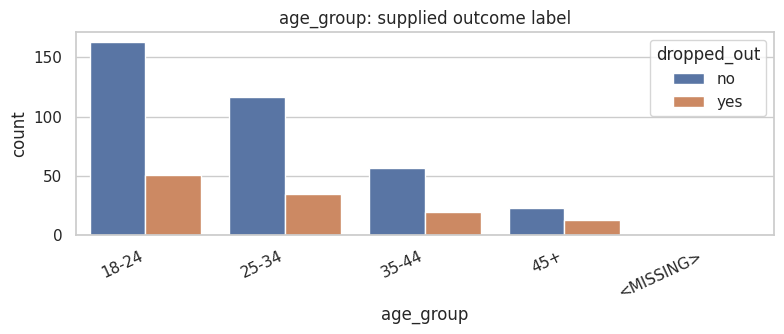


country vs supplied outcome


dropped_out,no,yes
country,,
Bangladesh,0.708,0.292
India,0.756,0.244
Kenya,0.829,0.171
Sri Lanka,0.760,0.240
UAE,0.703,0.297


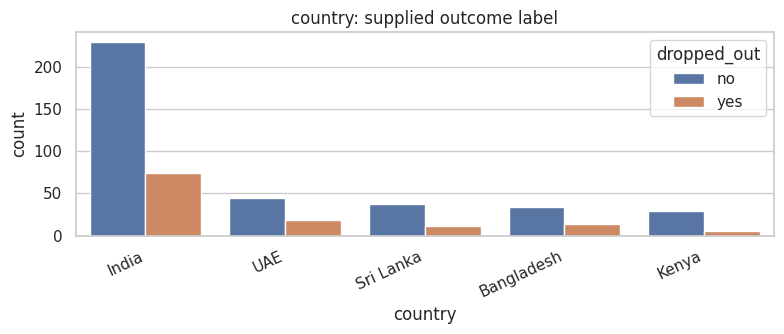


device vs supplied outcome


dropped_out,no,yes
device,,
<MISSING>,0.562,0.438
desktop,0.801,0.199
mobile,0.725,0.275
tablet,0.778,0.222


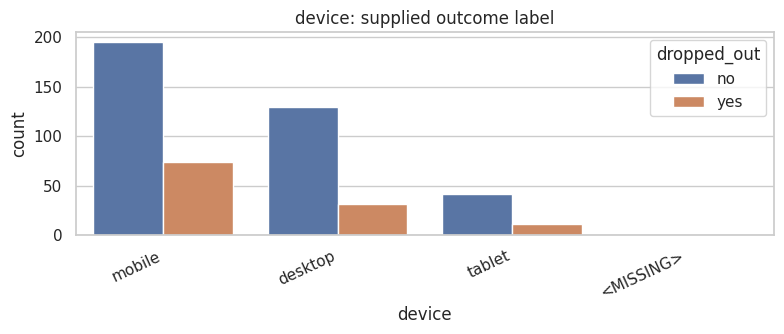


refund_requested vs supplied outcome


dropped_out,no,yes
refund_requested,,
no,0.950,0.050
yes,0.094,0.906


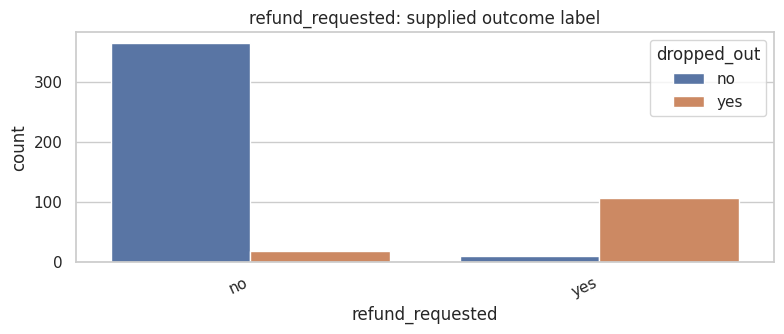

In [6]:
profile_features = [c for c in ["age_group", "country", "device", "refund_requested"] if c in base.columns]
profile_view = base[["student_id", "retrospective_group", "dropped_out", "proxy_target_A"] + profile_features].copy()
print("Profile-only candidate fields:", profile_features)
for col in profile_features:
    print(f"\n{col} vs supplied outcome")
    tab = pd.crosstab(profile_view[col].fillna("<MISSING>"), profile_view["dropped_out"], normalize="index")
    display(tab.round(3))
    plt.figure(figsize=(8, 3.5))
    sns.countplot(data=profile_view, x=col, hue="dropped_out", order=profile_view[col].fillna("<MISSING>").value_counts().index)
    plt.title(f"{col}: supplied outcome label")
    plt.xticks(rotation=25, ha="right"); plt.tight_layout(); plt.show()

## 5. Feature family B · 2–3 attempts (current + optional previous attempt)

This unit should not pretend both rows have the same history depth. A two-attempt student's penultimate point has one available attempt; a three-attempt student's penultimate point has two. Feature values such as `has_previous_attempt`, valid-score counts, and missingness are useful to expose that distinction. Do not fill absent history with zero.

Group B penultimate snapshots: 104

 Supplied eventual dropout label


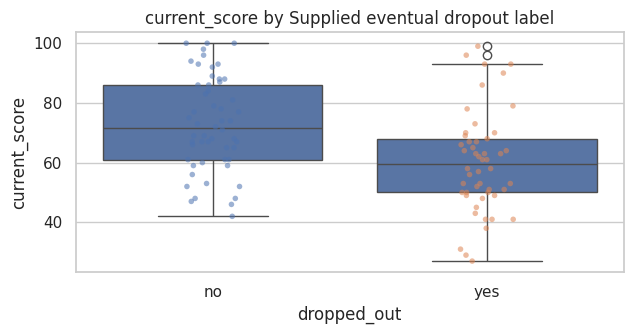

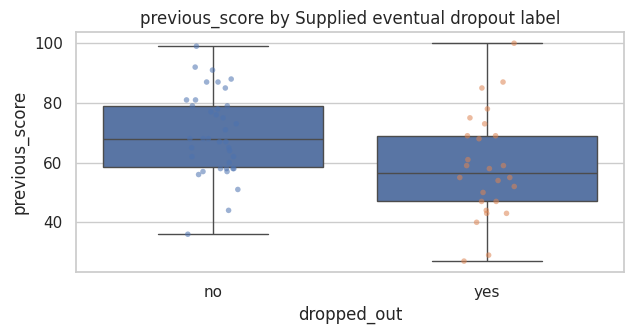

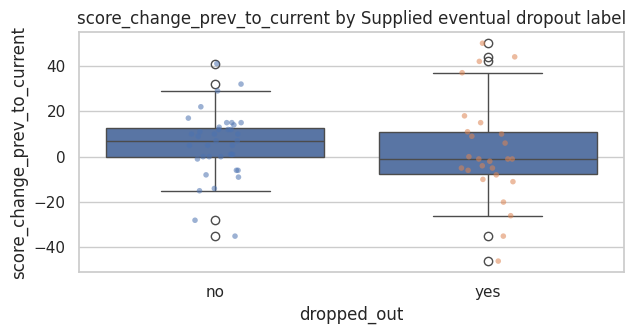

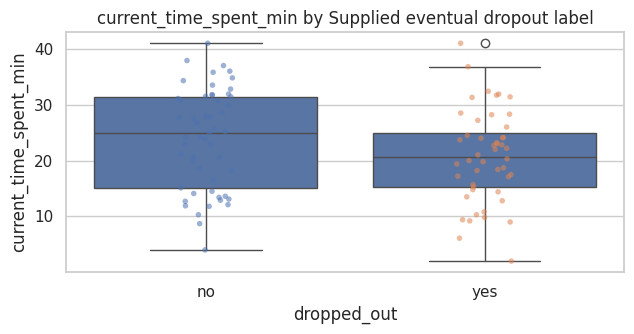

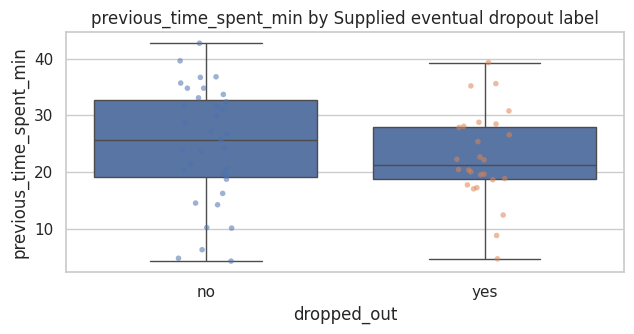

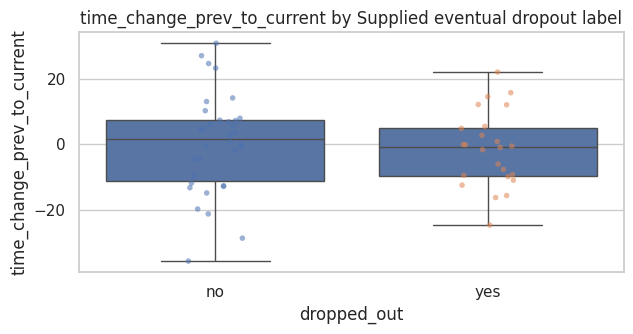

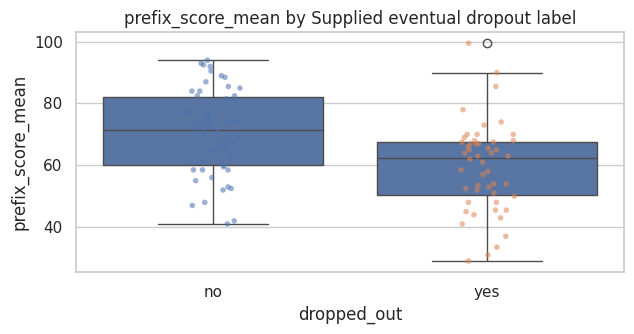

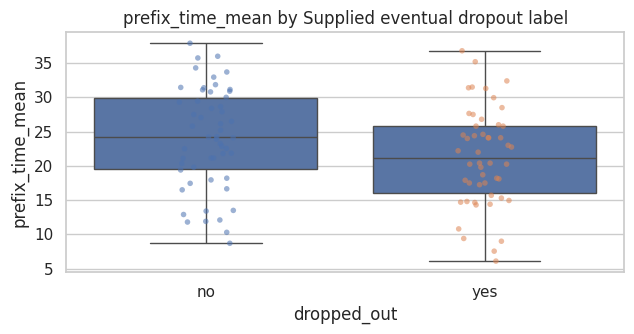

dropped_out,no,yes
prefix_attempts,,
1,0.400,0.600
2,0.594,0.406


dropped_out,no,yes
has_previous_attempt,,
False,0.400,0.600
True,0.594,0.406



 Bounded 2–3-attempt proxy label


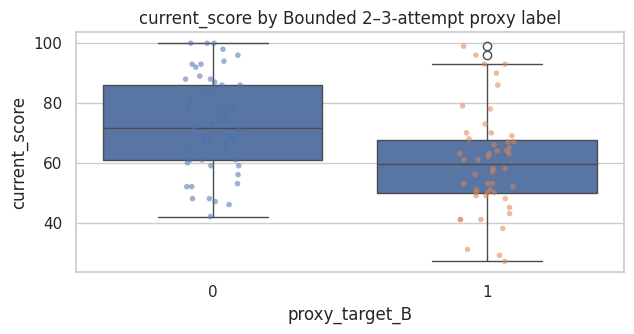

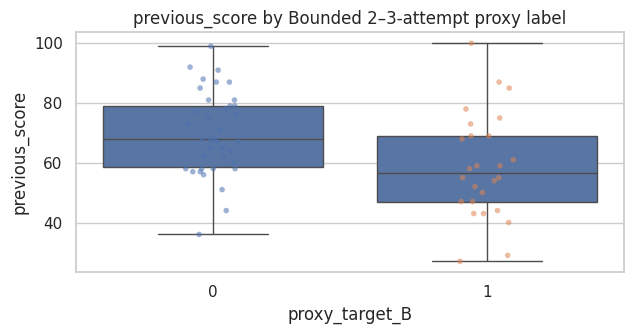

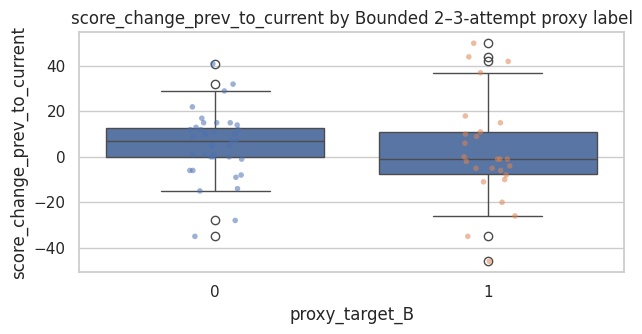

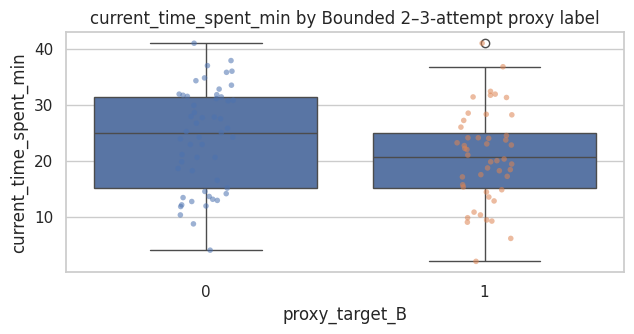

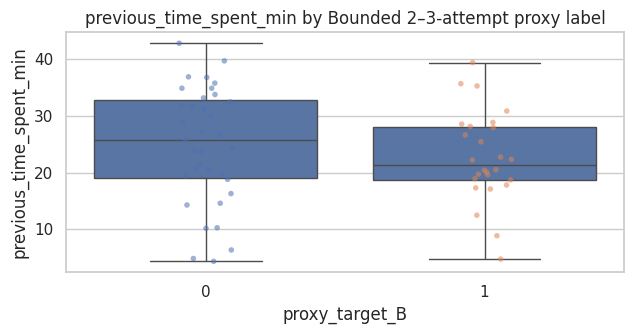

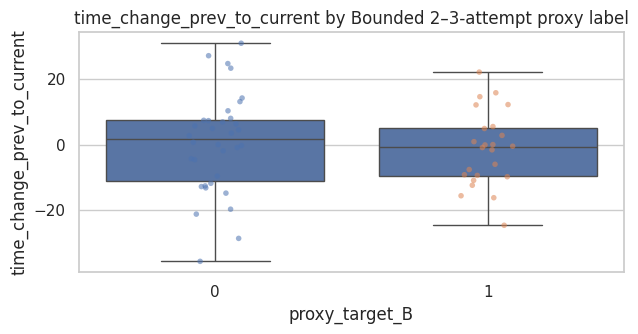

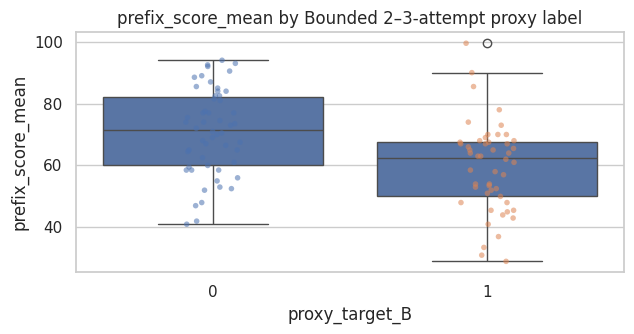

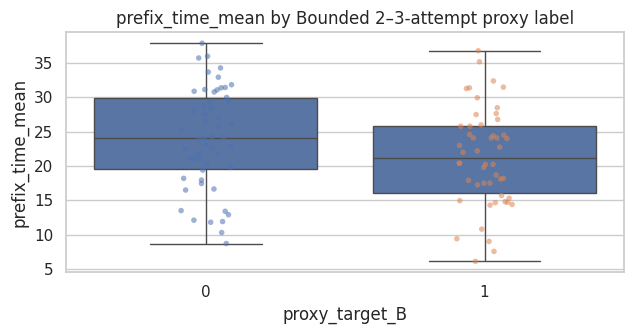

proxy_target_B,0,1
prefix_attempts,,
1,0.400,0.600
2,0.594,0.406


proxy_target_B,0,1
has_previous_attempt,,
False,0.400,0.600
True,0.594,0.406


In [7]:
group_b = snapshots[snapshots["retrospective_group"].eq("B: 2–3 attempts")].copy()
print("Group B penultimate snapshots:", len(group_b))
feature_b = ["current_score", "previous_score", "score_change_prev_to_current", "current_time_spent_min", "previous_time_spent_min", "time_change_prev_to_current", "prefix_score_mean", "prefix_time_mean", "prefix_attempts", "has_previous_attempt"]
for target_col, title in [("dropped_out", "Supplied eventual dropout label"), ("proxy_target_B", "Bounded 2–3-attempt proxy label")]:
    print("\n", title)
    for feat in feature_b:
        if feat not in group_b or group_b[feat].nunique(dropna=True) < 2: continue
        if group_b[feat].dtype == bool or group_b[feat].nunique(dropna=True) <= 8:
            display(pd.crosstab(group_b[feat].fillna("<MISSING>"), group_b[target_col], normalize="index").round(3))
        else:
            plt.figure(figsize=(6.5, 3.5))
            sns.boxplot(data=group_b, x=target_col, y=feat)
            sns.stripplot(data=group_b, x=target_col, y=feat, hue=target_col, dodge=False, alpha=.55, size=4, legend=False)
            plt.title(f"{feat} by {title}"); plt.tight_layout(); plt.show()

## 6. Feature family C · 4+ attempts (history and module profiles)

For the 4+ unit, the prefix includes multiple attempts and can support module-level summaries. Each aggregate is computed from the prefix only. We intentionally keep both *exposure* (attempt count) and *performance* (valid score statistics) separate.

In [8]:
def make_prefix_module_features(sid, prediction_order_index):
    # Use exact stable chronological row order, not only timestamp comparison: ties must not
    # accidentally admit a later attempt with the same timestamp.
    g = attempts_sorted[attempts_sorted["student_id"].eq(sid)].copy()
    g = g[g["_global_chronology_order"].le(prediction_order_index)]
    g = g[g["attempted_at"].notna()]
    out = {"student_id": sid}
    if g.empty: return out
    out["history_attempt_count"] = len(g)
    out["history_unique_modules"] = g["lesson_id"].nunique(dropna=True)
    out["history_valid_score_count"] = int(g["score_valid"].notna().sum())
    out["history_valid_duration_count"] = int(g["time_valid_min"].notna().sum())
    for lesson, m in g.groupby("lesson_id", dropna=False):
        tag = str(lesson).replace(" ", "_")
        out[f"{tag}__attempt_count"] = len(m)
        out[f"{tag}__valid_score_count"] = int(m["score_valid"].notna().sum())
        out[f"{tag}__score_mean"] = m["score_valid"].mean()
        out[f"{tag}__score_min"] = m["score_valid"].min()
        out[f"{tag}__score_std"] = m["score_valid"].std(ddof=0) if m["score_valid"].notna().sum() else np.nan
        out[f"{tag}__time_mean"] = m["time_valid_min"].mean()
        out[f"{tag}__time_sum"] = m["time_valid_min"].sum(min_count=1)
        out[f"{tag}__valid_duration_count"] = int(m["time_valid_min"].notna().sum())
    return out

snap_c = snapshots[snapshots["retrospective_group"].eq("C: 4+ attempts")].copy()
module_rows = [make_prefix_module_features(r.student_id, r.prediction_order_index) for r in snap_c.itertuples()]
module_features = pd.DataFrame(module_rows)
module_features = module_features.merge(snap_c[["student_id", "dropped_out", "proxy_target_C", "retrospective_group"]], on="student_id", how="left")
print("Group C snapshots:", len(snap_c), "Module feature matrix:", module_features.shape)
display(module_features.head())

Group C snapshots: 374 Module feature matrix: (374, 32)


,student_id,history_attempt_count,history_unique_modules,history_valid_score_count,history_valid_duration_count,L1__attempt_count,L1__valid_score_count,L1__score_mean,L1__score_min,L1__score_std,L1__time_mean,L1__time_sum,L1__valid_duration_count,L2__attempt_count,L2__valid_score_count,L2__score_mean,L2__score_min,L2__score_std,L2__time_mean,L2__time_sum,L2__valid_duration_count,L3__attempt_count,L3__valid_score_count,L3__score_mean,L3__score_min,L3__score_std,L3__time_mean,L3__time_sum,L3__valid_duration_count,dropped_out,proxy_target_C,retrospective_group
0,S002,6,3,6,5,2,2,68.0,59.0,9.0,44.7,89.4,2,3.0,3.0,65.333333,63.0,2.624669,17.25,34.5,2.0,1.0,1.0,49.0,49.0,0.0,28.20,28.2,1.0,no,0,C: 4+ attempts
1,S003,5,3,5,5,1,1,66.0,66.0,0.0,8.7,8.7,1,2.0,2.0,74.000000,70.0,4.000000,24.85,49.7,2.0,2.0,2.0,81.0,79.0,2.0,29.40,58.8,2.0,no,0,C: 4+ attempts
2,S005,6,3,6,6,2,2,98.5,97.0,1.5,30.2,60.4,2,2.0,2.0,47.000000,45.0,2.000000,35.15,70.3,2.0,2.0,2.0,60.5,50.0,10.5,26.05,52.1,2.0,no,0,C: 4+ attempts
3,S006,4,3,4,4,1,1,79.0,79.0,0.0,28.6,28.6,1,2.0,2.0,72.500000,66.0,6.500000,22.70,45.4,2.0,1.0,1.0,62.0,62.0,0.0,8.60,8.6,1.0,yes,1,C: 4+ attempts
4,S007,7,3,7,6,2,2,54.0,52.0,2.0,14.2,28.4,2,3.0,3.0,63.000000,52.0,11.575837,20.95,41.9,2.0,2.0,2.0,69.5,55.0,14.5,26.25,52.5,2.0,no,0,C: 4+ attempts


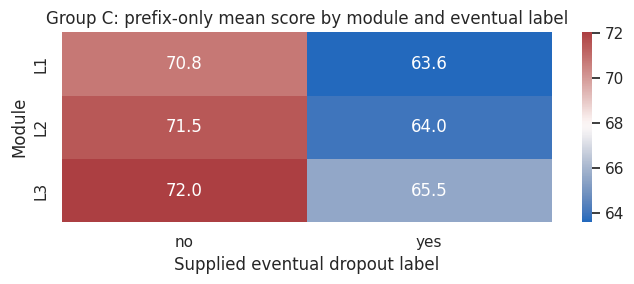

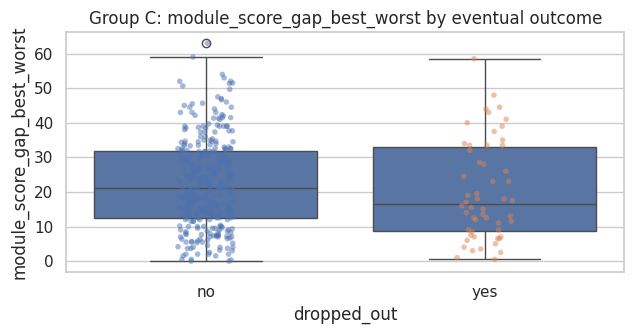

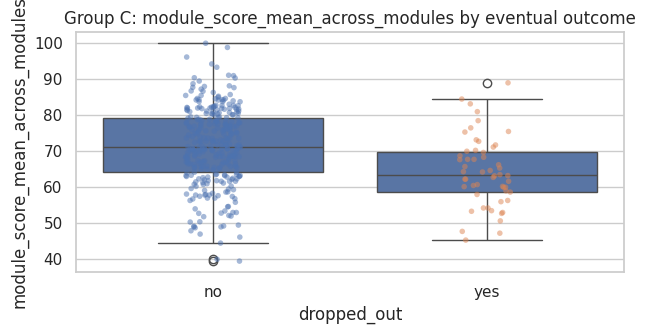

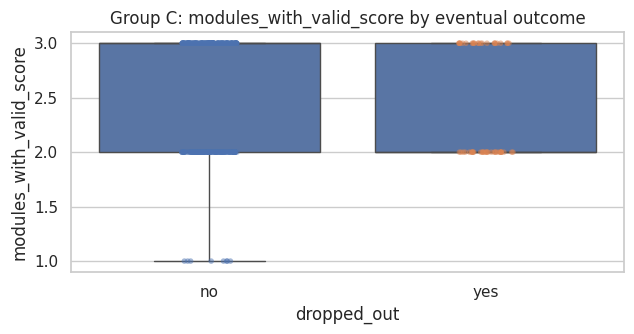

In [9]:
# Heatmap: average valid score by module and supplied label, calculated only from Group C prediction prefixes.
score_cols = [c for c in module_features.columns if c.endswith("__score_mean")]
if score_cols:
    heat = module_features.groupby("dropped_out")[score_cols].mean(numeric_only=True).T
    heat.index = [x.replace("__score_mean", "") for x in heat.index]
    plt.figure(figsize=(7, max(3, .45 * len(heat))))
    sns.heatmap(heat, annot=True, fmt=".1f", cmap="vlag", center=heat.stack().mean() if not heat.empty else 0)
    plt.title("Group C: prefix-only mean score by module and eventual label")
    plt.xlabel("Supplied eventual dropout label"); plt.ylabel("Module")
    plt.tight_layout(); plt.show()

# Compare module scores to detect subject-specific weaknesses. Require at least two modules with valid scores.
if score_cols:
    vals = module_features[score_cols]
    module_features["module_score_gap_best_worst"] = vals.max(axis=1, skipna=True) - vals.min(axis=1, skipna=True)
    module_features["module_score_mean_across_modules"] = vals.mean(axis=1, skipna=True)
    module_features["modules_with_valid_score"] = vals.notna().sum(axis=1)
    module_features.loc[module_features["modules_with_valid_score"] < 2, "module_score_gap_best_worst"] = np.nan
    for feat in ["module_score_gap_best_worst", "module_score_mean_across_modules", "modules_with_valid_score"]:
        plt.figure(figsize=(6.5, 3.5))
        sns.boxplot(data=module_features, x="dropped_out", y=feat)
        sns.stripplot(data=module_features, x="dropped_out", y=feat, hue="dropped_out", dodge=False, alpha=.5, size=4, legend=False)
        plt.title(f"Group C: {feat} by eventual outcome"); plt.tight_layout(); plt.show()

## 7. Visual comparison: feature candidates vs target

These plots are diagnostic, not proof of predictive value. Small groups, class imbalance, missingness, and retrospective labels can create misleading separation. Use scatter plots with hue for label, plus marginal/crosstab summaries where appropriate. For highly discrete features, prefer crosstabs over jittered scatter plots.

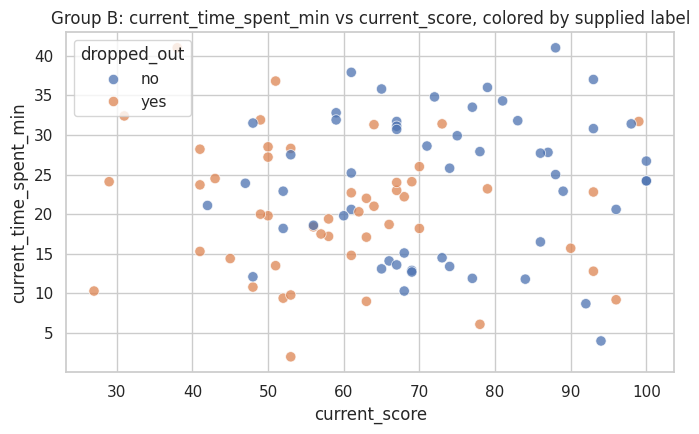

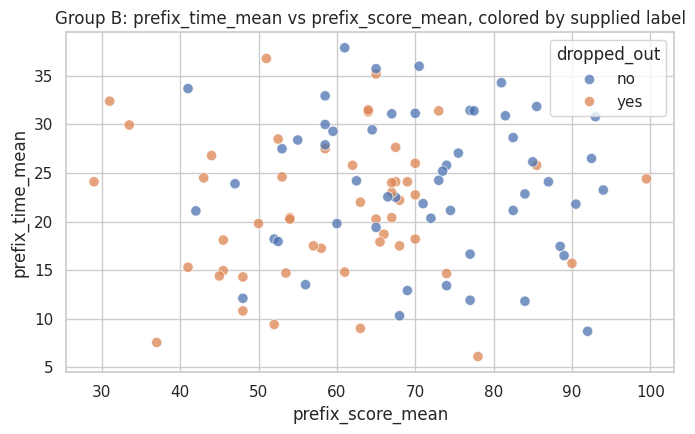

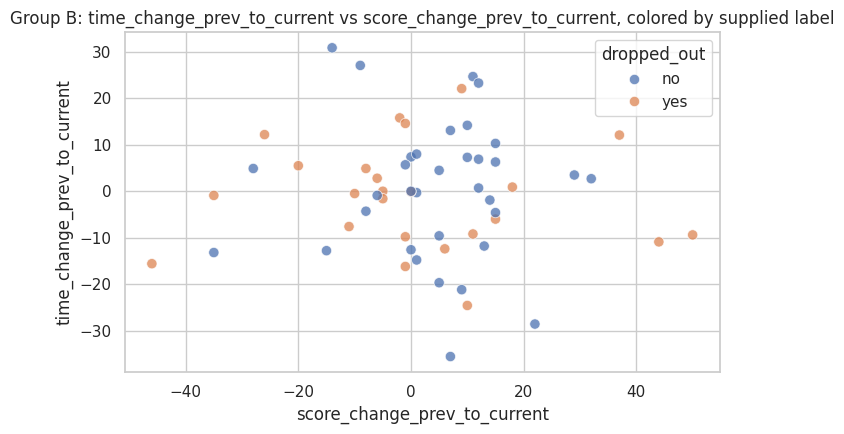


current_score: dropout rate by quantile bin (supplied label)


dropped_out,no,yes
current_score,,
"(26.999, 53.0]",0.276,0.724
"(53.0, 66.0]",0.417,0.583
"(66.0, 78.25]",0.680,0.320
"(78.25, 100.0]",0.731,0.269



current_time_spent_min: dropout rate by quantile bin (supplied label)


dropped_out,no,yes
current_time_spent_min,,
"(1.999, 15.1]",0.538,0.462
"(15.1, 22.9]",0.346,0.654
"(22.9, 28.6]",0.500,0.500
"(28.6, 41.0]",0.720,0.280



prefix_score_mean: dropout rate by quantile bin (supplied label)


dropped_out,no,yes
prefix_score_mean,,
"(28.999, 54.0]",0.259,0.741
"(54.0, 66.25]",0.480,0.520
"(66.25, 74.125]",0.500,0.500
"(74.125, 99.5]",0.846,0.154



prefix_time_mean: dropout rate by quantile bin (supplied label)


dropped_out,no,yes
prefix_time_mean,,
"(6.098999999999999, 17.5]",0.407,0.593
"(17.5, 22.925]",0.520,0.480
"(22.925, 28.025]",0.462,0.538
"(28.025, 37.9]",0.692,0.308


In [10]:
def scatter_by_target(df, x, y, target="dropped_out", title=None):
    plot_df = df[[x, y, target]].dropna().copy()
    if plot_df.empty:
        print(f"Skipping {x} vs {y}: no complete rows")
        return
    plt.figure(figsize=(7, 4.5))
    sns.scatterplot(data=plot_df, x=x, y=y, hue=target, alpha=.75, s=55)
    plt.title(title or f"{y} vs {x}, colored by {target}")
    plt.tight_layout(); plt.show()

for x, y in [("current_score", "current_time_spent_min"), ("prefix_score_mean", "prefix_time_mean"), ("score_change_prev_to_current", "time_change_prev_to_current")]:
    if x in group_b and y in group_b:
        scatter_by_target(group_b, x, y, title=f"Group B: {y} vs {x}, colored by supplied label")

# Binned cross-tabs help interpret continuous feature differences without implying linear boundaries.
for feat in ["current_score", "current_time_spent_min", "prefix_score_mean", "prefix_time_mean"]:
    if feat in group_b and group_b[feat].notna().sum() >= 5 and group_b[feat].nunique(dropna=True) > 5:
        binned = pd.qcut(group_b[feat], q=min(4, group_b[feat].nunique()), duplicates="drop")
        print(f"\n{feat}: dropout rate by quantile bin (supplied label)")
        display(pd.crosstab(binned, group_b["dropped_out"], normalize="index").round(3))

## 8. Explanation-derived features (candidate only; temporal leakage risk)

Explanation text may be useful, but first determine whether each explanation has a timestamp and whether it was created before the prediction point. The current explanations table has no timestamp in the known schema, so it cannot safely be joined to a historical prediction snapshot. Do not use text labels or explanation counts as temporal features until availability timing is established. The code below audits coverage only; it does not construct predictive text features.

In [11]:
print("Explanation columns:", explanations.columns.tolist())
print("Explanation rows:", len(explanations))
if "student_id" in explanations:
    exp_cov = explanations.groupby("student_id").size().rename("explanation_count")
    display(exp_cov.describe().to_frame("explanation_count_stats"))
    print("Students with at least one explanation:", int(exp_cov.index.nunique()))
if not any("date" in c.lower() or "time" in c.lower() for c in explanations.columns):
    print("WARNING: no explanation timestamp detected. Explanation-based features are not eligible for penultimate-time modeling without additional event-time evidence.")

Explanation columns: ['explanation_id', 'student_id', 'lesson_id', 'explanation_text', 'label']
Explanation rows: 724


,explanation_count_stats
count,426.000000
mean,1.699531
std,0.721991
min,1.000000
25%,1.000000
50%,2.000000
75%,2.000000
max,4.000000


Students with at least one explanation: 426


## 9. Feature catalogue: candidates, formulas, and guardrails

This catalogue is the handoff to feature engineering. All candidates should be generated from the information prefix available at the prediction point. Module identifiers are examples based on the current data; build module columns from the observed lesson catalogue rather than hard-coding a fixed list in production.

In [12]:
catalogue = pd.DataFrame([
    ("Profile", "age_group / country / device", "Student table", "At signup / before prediction", "Check fairness, privacy, missingness, and generalization."),
    ("Profile", "refund_requested", "Student table", "Only if confirmed available by prediction time", "May be downstream of disengagement; high leakage risk."),
    ("Current attempt", "current valid score / duration / lesson", "Current attempt only", "Current penultimate attempt", "999 score becomes missing; invalid/missing values flagged."),
    ("History", "previous score, score delta, time delta", "Previous + current attempts", "Only where prior attempt exists", "Do not impute missing prior attempt as zero."),
    ("History", "prefix mean / median / std / trend", "All attempts up to prediction point", "Prefix only", "Use valid score count and avoid future rows."),
    ("Module", "attempt count / unique exposure per module", "Prefix grouped by lesson", "Prefix only", "Exposure is not performance; no attempts is not score zero."),
    ("Module", "mean/min/std score per module", "Valid prefix scores by lesson", "Prefix only", "Require valid-score count; 999 excluded."),
    ("Module", "mean/sum time per module", "Valid prefix durations by lesson", "Prefix only", "Missing duration not zero; inspect skew and outliers."),
    ("Cross-module", "best-worst score gap / cross-module std", "At least 2 modules with valid scores", "Prefix only", "Undefined for one observed module; keep missing."),
    ("Progression", "per-module first-to-latest score change", "Within-prefix attempts per lesson", "Prefix only", "Only defined if at least two valid scores in module."),
    ("Data quality", "valid score count / missing score rate", "Prefix attempt records", "Prefix only", "Missingness can be informative but also operational."),
    ("Timing", "days since signup / gap from prior attempt", "Signup + prefix timestamps", "Current time minus prior time", "Do not use gap to the next/final attempt."),
    ("Explanations", "explanation count / text embedding / label", "Explanations table", "Not currently safe", "No event timestamp: exclude until timing is established."),
    ("Forbidden", "eventual attempt count / last attempt date / final score", "Complete history", "Future-derived", "Never use as predictors at penultimate prediction point."),
], columns=["family", "candidate feature", "source", "availability requirement", "caveat / guardrail"])
display(catalogue)

,family,candidate feature,source,availability requirement,caveat / guardrail
0,Profile,age_group / country / device,Student table,At signup / before prediction,"Check fairness, privacy, missingness, and gene..."
1,Profile,refund_requested,Student table,Only if confirmed available by prediction time,May be downstream of disengagement; high leaka...
2,Current attempt,current valid score / duration / lesson,Current attempt only,Current penultimate attempt,999 score becomes missing; invalid/missing val...
3,History,"previous score, score delta, time delta",Previous + current attempts,Only where prior attempt exists,Do not impute missing prior attempt as zero.
4,History,prefix mean / median / std / trend,All attempts up to prediction point,Prefix only,Use valid score count and avoid future rows.
5,Module,attempt count / unique exposure per module,Prefix grouped by lesson,Prefix only,Exposure is not performance; no attempts is no...
6,Module,mean/min/std score per module,Valid prefix scores by lesson,Prefix only,Require valid-score count; 999 excluded.
7,Module,mean/sum time per module,Valid prefix durations by lesson,Prefix only,Missing duration not zero; inspect skew and ou...
8,Cross-module,best-worst score gap / cross-module std,At least 2 modules with valid scores,Prefix only,Undefined for one observed module; keep missing.
9,Progression,per-module first-to-latest score change,Within-prefix attempts per lesson,Prefix only,Only defined if at least two valid scores in m...


## 10. Final checklist before turning candidates into datasets

- [ ] Decide whether the target is **eventual supplied dropout status** or the proposed **attempt-boundary proxy target**. Do not conflate them.
- [ ] Define the prediction timestamp for the 0–1, 2–3, and 4+ units precisely.
- [ ] Verify whether profile fields such as `refund_requested` exist at prediction time.
- [ ] Resolve timestamp ties, invalid timestamps, duplicate attempt IDs, and missing timestamps.
- [ ] Keep `999` out of all valid score statistics; retain an invalid-score flag/count.
- [ ] Never encode unattempted modules as zero score or zero time.
- [ ] Include valid-observation counts beside each mean/median/std.
- [ ] Build module aggregates only from attempts at or before the prediction point.
- [ ] Do not use eventual attempt count, final attempt details, next-attempt gaps, or final outcome-derived fields as predictors.
- [ ] Split train/validation/test by student, not by attempt row, when modeling begins.
- [ ] Inspect target counts and confidence intervals before trusting apparent class separation.
- [ ] Keep this notebook exploratory: no training datasets are exported and no model is fitted.

**Output of this notebook:** a documented feature catalogue, in-memory example prefix snapshots, plots and crosstabs to compare candidate features against both supplied outcome and exploratory proxy targets, plus an explicit list of unresolved assumptions.